# Kd(490) trend over the DBO — **true per-pixel** map, scorecard estimator

Rebuild of the Kd(490) trend map so that it matches the published DBO trend figures in two ways the
old `1_pull_data/05_modis-kd490-8day.ipynb` map did not:

1. **Every pixel is fit.** The old map used `S = 7`: it fit one pixel in every 49 and painted that
   single fit across the surrounding 7×7 block (~28 km). That is why it looked blocky, and why
   calling it "per-pixel" was wrong. Here `STRIDE = 1` and the estimator is **vectorised**, so a full
   4 km fit is minutes rather than hours.
2. **The scorecard estimator.** The old map trended the *annual mean*, which mixes a changing
   open-water season into the trend. This notebook uses the same series and estimator as
   the Fig. 8 scorecard and `2_figures/fig02_trend-maps-chl-bbp-adg.ipynb`: monthly means → **month-of-year
   anomaly** → Theil–Sen → **%/decade of the pixel's own record mean**, with an AR(1)-adjusted
   Mann–Kendall p.

Styling follows `2_figures/fig02_trend-maps-chl-bbp-adg.ipynb`: diverging %/decade fill, dotted hatching where the
**pixel** trend is significant, and a **thick yellow box** where that **box-wide mean** trend is
significant (p < 0.05) — the box test, not the pixels inside it.

Everything streams from OB.DAAC through `earthaccess`; nothing is downloaded
permanently. Peak memory is ~3–4 GB for the monthly stack plus whatever `MEM_BUDGET_GB` allows for
the pairwise chunks.

> Expected result, from the published scorecard: **DBO1, DBO2 and DBO3 significant** (8.3, 12.1,
> 7.2 %/dec), DBO4 and DBO5 not. Section 11 checks that this notebook reproduces those numbers before
> the figure is drawn — if it does not, the figure is wrong and the mismatch is the finding.

## 1. Imports

In [3]:
import time as _time, warnings, gc, pickle
from pathlib import Path
from datetime import date
import numpy as np, pandas as pd, xarray as xr
import earthaccess
from pyresample import AreaDefinition, geometry
from pyresample.kd_tree import resample_nearest
from matplotlib.path import Path as MplPath
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator
import cartopy.crs as ccrs, cartopy.feature as cfeature
from concurrent.futures import ThreadPoolExecutor, wait, FIRST_COMPLETED
from scipy.stats import theilslopes, kendalltau, norm
warnings.filterwarnings("ignore")
print("imports OK")

imports OK


## 2. Configuration

Grid, box corners and the estimator knobs are copied verbatim from
`2_figures/fig02_trend-maps-chl-bbp-adg.ipynb` so this map is directly comparable to the chl / b$_{bp}$ / a$_{dg}$
panels. The only changes are the product (Kd_490) and `STRIDE = 1`.

In [4]:
# ---------------------------------------------------------------- grid, region, boxes
# The scorecard's ocean-colour rows run 2002-2025; keep END_DATE there so section 11 can reproduce
# them. Set END_DATE = date.today() to extend the map past 2025 (then the QC will differ by design).
START_DATE, END_DATE = date(2002, 7, 1), date(2025, 12, 31)
DBO_BBOX = (-180.0, 50.0, -124.0, 74.0)      # coarse lon/lat pre-subset before regridding
ROI, N_WORKERS = 6_000, 8                     # nearest-neighbour radius (m); L3m is 4 km

dbo_area = AreaDefinition(
    "ease2_north_dbo_4km", "EASE-Grid 2.0 North: Aleutians -> Beaufort (DBO1-8), 4 km", "EPSG:6931",
    {"proj": "laea", "lat_0": 90, "lon_0": 0, "x_0": 0, "y_0": 0, "datum": "WGS84", "units": "m"},
    906, 845, (-3_624_000, 992_000, 0, 4_372_000))
ny, nx = dbo_area.shape
data_crs = ccrs.LambertAzimuthalEqualArea(central_latitude=90, central_longitude=0)
disp     = ccrs.LambertAzimuthalEqualArea(central_latitude=90, central_longitude=-152)
x0, y0, x1, y1 = dbo_area.area_extent

DBO_BOXES = {
    "DBO1": [(63.769462,-172.312422),(61.945988,-172.186927),(61.846516,-175.790978),(63.662718,-176.147111)],
    "DBO2": [(65.107747,-170.865176),(65.097001,-167.859549),(64.481828,-167.907758),(64.493658,-170.840669)],
    "DBO3": [(66.785880,-171.330008),(68.608869,-171.419334),(68.572412,-166.481029),(66.752281,-166.755808)],
    "DBO4": [(71.994000,-164.226000),(71.801000,-159.729000),(70.641000,-160.305000),(70.821000,-164.556000)],
    "DBO5": [(71.807730,-158.537691),(71.635583,-155.931220),(71.110941,-156.307277),(71.278277,-158.847920)],
    "DBO6": [(71.850000,-150.108000),(70.890000,-150.976000),(71.159000,-153.865000),(72.119000,-152.980000)],
    "DBO7": [(70.868000,-141.528000),(69.946000,-142.679000),(70.333000,-145.439000),(71.253000,-144.256000)],
    "DBO8": [(70.834000,-125.155000),(70.049000,-126.997000),(70.664000,-129.354000),(71.442000,-127.431000)],
}
SCORECARD_BOXES = ["DBO1", "DBO2", "DBO3", "DBO4", "DBO5"]   # the five columns of the table

# ---------------------------------------------------------------- product
KD_CONCEPT = "C3380709198-OB_CLOUD"           # MODISA_L3m_KD
KD_PERIOD  = "8D"                             # "8D" = scorecard definition | "MO" = ~4x faster first look
KD_PATTERN = f"*.{KD_PERIOD}.KD.Kd_490.4km.nc"
KD_VAR     = "Kd_490"
PANEL_LABEL, UNIT_LABEL = r"$K_d$(490)  attenuation", "%/decade"

# ---------------------------------------------------------------- analysis knobs
STRIDE     = 1      # 1 = every pixel (the point of this notebook). 2-3 for a fast preview.
MIN_MONTHS = 60     # monthly anomalies required before a pixel is trended
MIN_YEARS  = 15     # ... and they must span at least this many years
SIG        = 0.05
MEM_BUDGET_GB = 1.5 # working memory for the pairwise Theil-Sen chunks (see section 8)

# ---------------------------------------------------------------- figure knobs
EXTENT   = (-179, -124, 59, 74)     # crops the Gulf of Alaska so the DBO boxes are legible
FIG_W    = 16
FS_TITLE, FS_CBAR, FS_TICK, FS_GRID, FS_BOX, FS_LEG = 26, 30, 26, 16, 16, 22
CBAR_ASPECT, CBAR_SHRINK, CBAR_PAD, CBAR_NBINS = 11, 1.0, 0.015, 6
SIG_BOX_COLOR, SIG_BOX_LW = "#ffd400", 4.0   # yellow + thick == this box's trend is significant
SIG_BOX_HALO = "#2b2200"                     # dark casing: bare yellow vanishes on pale water/ice
NS_BOX_COLOR, NS_BOX_LW = "#111111", 1.2
LABEL_NUDGE = {"DBO4": (-0.8, 0.15), "DBO5": (0.0, 1.35), "DBO6": (0.9, 0.15)}

# ---------------------------------------------------------------- paths
OUT_DIR  = Path.home() / "ADD_YOUR_PATH" / "kd490"; OUT_DIR.mkdir(parents=True, exist_ok=True)  # add your path
OUT_STEM = "kd490_trend_map_perpixel_monthly_anom"
CKPT_DIR = Path.home() / "kd490_perpixel_ckpt"; CKPT_DIR.mkdir(exist_ok=True)  # add your path
CHECKPOINT = True
# The old annual-mean notebook's checkpoint holds per-composite box means under "box_rows".
# If it is on disk the box series is free; otherwise it is folded out of this notebook's stream.
LEGACY_CKPT = (Path.home() / "modis_kd490_dbo_8d_ckpt.pkl", "box_rows")  # add your path

# published the Fig. 8 scorecard Kd(490) values, for the QC in section 11: (%/dec, p_AR1)
SCORECARD_KD = {"DBO1": (8.3, 0.0014), "DBO2": (12.1, 0.0083), "DBO3": (7.2, 0.023),
                "DBO4": (1.5, 0.519),  "DBO5": (2.2, 0.556)}

MONTHS = pd.period_range(START_DATE, END_DATE, freq="M")
MIDX   = {(p.year, p.month): i for i, p in enumerate(MONTHS)}
MOY    = np.array([p.month for p in MONTHS])
DECYR  = np.array([p.year + (p.month - 0.5) / 12.0 for p in MONTHS], float)
print(f"grid {dbo_area.shape} | {len(MONTHS)} months {MONTHS[0]} -> {MONTHS[-1]} | "
      f"Kd from {KD_PERIOD} composites | STRIDE={STRIDE}")

grid (845, 906) | 282 months 2002-07 -> 2025-12 | Kd from 8D composites | STRIDE=1


## 3. Auth + granule search

In [5]:
auth = earthaccess.login(persist=True)

def _search(concept, pattern, limit=12000):
    for k in range(5):
        try:
            return earthaccess.search_data(concept_id=concept, granule_name=pattern,
                                           temporal=(START_DATE.isoformat(), END_DATE.isoformat()),
                                           count=limit)
        except Exception as ex:
            print("  retry:", str(ex)[:80]); _time.sleep(2 * (k + 1))
    raise RuntimeError(f"CMR search failed for {pattern}")

def _gdate(g, monthly):
    d = g.data_links()[0].rsplit("/", 1)[-1].split(".")[1].split("_")[0]
    return date(int(d[:4]), int(d[4:6]), 1 if monthly else int(d[6:8]))

gs = _search(KD_CONCEPT, KD_PATTERN)
gran = {}
for g in gs:
    gran.setdefault(_gdate(g, KD_PERIOD == "MO"), g)
print(f"Kd_490: {len(gs)} granules | {len(gran)} time steps ({min(gran)} -> {max(gran)})")
print("example:", gs[0].data_links()[0].rsplit('/', 1)[-1])

Kd_490: 1284 granules | 1081 time steps (2002-07-04 -> 2025-12-27)
example: AQUA_MODIS.20020704_20020711.L3m.8D.KD.Kd_490.4km.nc


## 4. Reader — one granule → one array on the EASE-2 DBO grid

Identical to the other notebooks: nearest-neighbour regrid with `radius_of_influence = 6 km` onto the
4 km grid, non-positive values dropped. Kd_490 is strictly positive, so `v > 0` also clears fills.

In [6]:
def _read_l3m(f, var):
    """L3m global grid -> (lat1d, lon1d, values) inside DBO_BBOX; non-positive -> NaN."""
    with xr.open_dataset(f, engine="h5netcdf") as ds:
        lat = np.asarray(ds["lat"].values, float); lon = np.asarray(ds["lon"].values, float)
        lo0, la0, lo1, la1 = DBO_BBOX
        jl = np.where((lat >= la0) & (lat <= la1))[0]; il = np.where((lon >= lo0) & (lon <= lo1))[0]
        if jl.size == 0 or il.size == 0: return None
        sub = ds[var].isel(lat=slice(int(jl[0]), int(jl[-1]) + 1), lon=slice(int(il[0]), int(il[-1]) + 1))
        v  = np.asarray(sub.values, float).squeeze()
        la = np.asarray(sub["lat"].values, float); lo = np.asarray(sub["lon"].values, float)
    return la, lo, np.where(v > 0, v, np.nan)

def _to_grid(la, lo, v):
    lon2d, lat2d = np.meshgrid(lo, la); m = np.isfinite(v)
    if not m.any(): return np.full(dbo_area.shape, np.nan, np.float32)
    sw = geometry.SwathDefinition(lons=np.where(lon2d > 180, lon2d - 360, lon2d)[m], lats=lat2d[m])
    return resample_nearest(sw, v[m], dbo_area, radius_of_influence=ROI,
                            fill_value=np.nan, reduce_data=False).astype(np.float32)

def project_one(granule, var=KD_VAR):
    f = earthaccess.open([granule], show_progress=False)[0]
    try: out = _read_l3m(f, var)
    finally:
        try: f.close()
        except Exception: pass
    if out is None: return np.full(dbo_area.shape, np.nan, np.float32)
    return _to_grid(*out)
print("reader ready")

reader ready


## 5. DBO box masks on the EASE-2 grid

In [7]:
lons2d, lats2d = dbo_area.get_lonlats()
grid_pts = np.column_stack([lons2d.ravel(), lats2d.ravel()])
box_masks = {n: MplPath([(lo, la) for la, lo in c] + [(c[0][1], c[0][0])])
                   .contains_points(grid_pts).reshape(lons2d.shape)
             for n, c in DBO_BOXES.items()}
for n, m in box_masks.items(): print(f"  {n}: {int(m.sum()):>6,} cells")

  DBO1:  2,412 cells
  DBO2:    605 cells
  DBO3:  2,561 cells
  DBO4:  1,293 cells
  DBO5:    351 cells
  DBO6:    739 cells
  DBO7:    773 cells
  DBO8:    760 cells


## 6. Trend estimator — one function, used for pixels and for boxes

`theilsen_mk_ar1` is byte-for-byte the helper from `fig02_trend-maps-chl-bbp-adg.ipynb`, so any disagreement
between this notebook and the scorecard is a data or series difference, never an estimator
difference. Section 8 vectorises exactly this arithmetic and section 9 proves the two agree.

In [8]:
def _lag1(r):
    r = np.asarray(r, float); a, b = r[1:], r[:-1]; v = np.isfinite(a) & np.isfinite(b)
    return float(np.corrcoef(a[v], b[v])[0, 1]) if v.sum() >= 10 else 0.0

def theilsen_mk_ar1(x, y, minn=8):
    """Theil-Sen slope (y-units/yr) + MK p, naive and AR(1)-variance-adjusted."""
    v = np.isfinite(x) & np.isfinite(y); x, y = np.asarray(x)[v], np.asarray(y)[v]; n = len(x)
    if n < minn:
        return dict(slope=np.nan, p_naive=np.nan, p_adj=np.nan, phi=np.nan, n=n, n_eff=np.nan)
    slope, intercept, _, _ = theilslopes(y, x)
    tau, p_naive = kendalltau(x, y)
    sl, ic = np.polyfit(x, y, 1); phi = _lag1(y - (sl * x + ic))
    n_eff = n * (1 - phi) / (1 + phi) if (abs(phi) < 1 and phi != 0) else n
    p_adj = (2 * (1 - norm.cdf(abs(tau / np.sqrt(2 * (2 * n_eff + 5) / (9 * n_eff * (n_eff - 1))))))
             if n_eff > 4 else np.nan)
    return dict(slope=slope, p_naive=p_naive, p_adj=p_adj, phi=phi, n=n, n_eff=n_eff)

def monthly_anomaly(values):
    """values on the MONTHS axis -> month-of-year anomaly, in the same (linear) units."""
    v = np.asarray(values, float)
    clim = np.array([np.nanmean(v[MOY == m]) if np.isfinite(v[MOY == m]).any() else np.nan
                     for m in range(1, 13)])
    return v - clim[MOY - 1]

def trend_pct_per_decade(values):
    """The scorecard recipe on one monthly series: %/decade of the record mean + AR(1) MK p."""
    v = np.asarray(values, float); base = np.nanmean(v)
    if not np.isfinite(base) or base == 0:
        return dict(pct=np.nan, p_adj=np.nan, n=0, n_eff=np.nan, phi=np.nan)
    a = monthly_anomaly(v); ok = np.isfinite(a)
    if ok.sum() < MIN_MONTHS or (DECYR[ok].max() - DECYR[ok].min()) < MIN_YEARS:
        return dict(pct=np.nan, p_adj=np.nan, n=int(ok.sum()), n_eff=np.nan, phi=np.nan)
    r = theilsen_mk_ar1(DECYR[ok], a[ok])
    return dict(pct=r["slope"] * 10 / base * 100, p_adj=r["p_adj"], n=r["n"],
                n_eff=r["n_eff"], phi=r["phi"])

def _stars(p):
    return ("***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else "ns") if np.isfinite(p) else "n/a"
print("estimator ready")

estimator ready


## 7. Streaming — composite → per-pixel monthly means (+ per-box series)

A `(month, y, x)` sum and count, folded as granules arrive. The count is per *composite*, so a month
holding four 8-day composites averages all four. Checkpointed, so an interrupted stream resumes.

Memory: the sum is float32 `(len(MONTHS), 845, 906)` ≈ **0.9 GB** and the count uint16 ≈ 0.5 GB.

In [9]:
class MonthlyAccum:
    """Per-pixel monthly sums/counts + per-composite box means, checkpointable."""
    def __init__(self, name):
        self.name = name
        self.s = np.zeros((len(MONTHS), ny, nx), np.float32)
        self.c = np.zeros((len(MONTHS), ny, nx), np.uint16)
        self.box, self.done = {}, set()

    def fold(self, d, arr):
        i = MIDX.get((d.year, d.month))
        if i is None: return
        m = np.isfinite(arr)
        self.s[i][m] += arr[m]; self.c[i][m] += 1
        self.box[d] = {n: (float(np.mean(arr[mm])) if (mm := (mask & m)).any() else np.nan)
                       for n, mask in box_masks.items()}
        self.done.add(d)

    def means(self):
        """(month, y, x) monthly means; months with no observation are NaN."""
        out = self.s / np.maximum(self.c, 1)
        out[self.c == 0] = np.nan
        return out

    def box_monthly(self):
        df = pd.DataFrame(self.box).T.sort_index()
        df.index = pd.to_datetime(df.index)
        return df.resample("MS").mean()

    def save(self):
        if not CHECKPOINT: return
        p = CKPT_DIR / f"{self.name}_{KD_PERIOD}"
        np.save(p.with_suffix(".s.npy"), self.s); np.save(p.with_suffix(".c.npy"), self.c)
        pickle.dump({"box": self.box, "done": self.done}, open(p.with_suffix(".meta.pkl"), "wb"))

    def load(self):
        p = CKPT_DIR / f"{self.name}_{KD_PERIOD}"
        if not (CHECKPOINT and p.with_suffix(".meta.pkl").exists()): return False
        self.s = np.load(p.with_suffix(".s.npy")); self.c = np.load(p.with_suffix(".c.npy"))
        meta = pickle.load(open(p.with_suffix(".meta.pkl"), "rb"))
        self.box, self.done = meta["box"], meta["done"]
        print(f"  resumed: {len(self.done)} composites already folded")
        return True

def stream_kd(ckpt_every=1000):
    acc = MonthlyAccum("kd490"); acc.load()
    items = sorted(d for d in gran if d not in acc.done)
    if not items:
        print(f"nothing to stream ({len(acc.done)} composites already folded)"); return acc

    def _one(d):
        try: return d, project_one(gran[d]), None
        except Exception as e: return d, None, f"{type(e).__name__}: {str(e)[:60]}"

    t0 = _time.time(); nok = nfail = since = 0
    print(f"{len(acc.done)} done | streaming {len(items)} composites with {N_WORKERS} workers...")
    with ThreadPoolExecutor(max_workers=N_WORKERS) as ex:
        src = iter(items); fs = set()
        for _ in range(N_WORKERS * 2):
            try: fs.add(ex.submit(_one, next(src)))
            except StopIteration: break
        while fs:
            dn, fs = wait(fs, return_when=FIRST_COMPLETED)
            for fut in dn:
                d, arr, err = fut.result()
                if arr is None:
                    nfail += 1
                    if nfail <= 8: print(f"   X {d} {err}")
                else:
                    acc.fold(d, arr); nok += 1; since += 1
                    if nok % 250 == 0:
                        print(f"   {nok}/{len(items)} ok, {nfail} fail ({(_time.time()-t0)/60:.1f} min)")
                    if since >= ckpt_every: acc.save(); since = 0
                try: fs.add(ex.submit(_one, next(src)))
                except StopIteration: pass
    acc.save()
    print(f"folded {nok} composites ({nfail} failed) in {(_time.time()-t0)/60:.1f} min")
    return acc
print("streamer ready")

streamer ready


## 8. Per-pixel trends — vectorised

The scalar loop in section 6 costs ~2 ms per pixel; at 765,000 pixels that is **~25 minutes of pure
Python per pass**, which is why the old map strided by 7. This does the identical arithmetic on
whole blocks of pixels at once:

| scalar | vectorised here |
|---|---|
| `theilslopes(y, x)` | median over all *i&lt;j* of `(y_j − y_i)/(x_j − x_i)` |
| `kendalltau(x, y)` | `Σ sign(y_j − y_i) / (n(n−1)/2)` — `DECYR` is strictly increasing so `sign(dx) ≡ +1` |
| `_lag1(resid)` | Pearson r of the OLS residuals at lag 1, on the **valid points packed in time order** (same as the scalar, which compresses to `y[v]` first) |
| `n_eff`, `p_adj` | same closed form |

Two things make it affordable. All-NaN months are dropped from the time axis first — in the Arctic,
ocean colour only exists roughly April–September, so this alone cuts the pair count ~3×. And the
pixels are processed in chunks sized to `MEM_BUDGET_GB`, since the pairwise array is
`n(n−1)/2 × chunk` floats.

> **float64 is not optional.** Section 9 measures it: doing the anomaly in the stack's native
> float32 leaves a ~2e-4 %/decade gap against the scalar path. Harmless for a colour scale, but it
> would make the verification below fail for the wrong reason, so the working copy is promoted to
> float64. The empty months are dropped *first*, which halves that copy.

In [10]:
def pixel_trends_full(stack, stride=None, mem_budget_gb=None, verbose=True):
    """(month,y,x) monthly means -> (%/decade, p_AR1) at EVERY pixel.

    Vectorised equivalent of `theilsen_mk_ar1` applied pixel-by-pixel. CONSUMES `stack`
    (converted to month-of-year anomalies in place when stride == 1).
    """
    S   = STRIDE if stride is None else stride
    bud = (MEM_BUDGET_GB if mem_budget_gb is None else mem_budget_gb) * 1024**3
    src = stack if S == 1 else stack[:, ::S, ::S]
    nys, nxs = src.shape[1:]

    # --- drop months that are empty everywhere (polar night / no ocean colour) BEFORE promoting
    #     to float64: in the Arctic that is ~half the axis, so it halves the working copy.
    keep_t = np.isfinite(src).any(axis=(1, 2))
    X, MOY_T = DECYR[keep_t], MOY[keep_t]
    W  = src[keep_t].astype(np.float64)          # trimmed float64 working copy; `stack` is untouched
    nt = W.shape[0]
    if verbose:
        print(f"time axis {len(DECYR)} -> {nt} months with data | "
              f"{nt*(nt-1)//2:,} pairs per pixel")

    # --- record mean (the %-normalisation base) BEFORE the anomaly is taken ---
    base = np.nanmean(W, axis=0).ravel()

    # --- month-of-year anomaly, in place on the working copy ---
    clim = np.stack([np.nanmean(W[MOY_T == m], axis=0) if (MOY_T == m).any()
                     else np.full((nys, nxs), np.nan) for m in range(1, 13)])
    W -= clim[MOY_T - 1]
    del clim
    A = W.reshape(nt, -1)

    # --- which pixels qualify (same gates as trend_pct_per_decade) ---
    ok   = np.isfinite(A)
    cnt  = ok.sum(0)
    first = np.argmax(ok, axis=0)                       # X is increasing -> first/last valid give the span
    last  = nt - 1 - np.argmax(ok[::-1], axis=0)
    span  = np.where(cnt > 0, X[last] - X[first], 0.0)
    keep  = (cnt >= MIN_MONTHS) & (span >= MIN_YEARS) & np.isfinite(base) & (base != 0)
    cols_all = np.where(keep)[0]
    del ok, first, last, span

    slope_pct = np.full(A.shape[1], np.nan)
    padj      = np.full(A.shape[1], np.nan)
    if cols_all.size == 0:
        print("no pixel passes the gates");
        up = lambda a: a.reshape(nys, nxs) if S == 1 else np.kron(a.reshape(nys, nxs), np.ones((S, S)))[:ny, :nx]
        return up(slope_pct), up(padj)

    ii, jj = np.triu_indices(nt, k=1)
    DX = (X[jj] - X[ii])[:, None]
    npair = ii.size
    # pairwise block is npair x chunk float64, and dy/dx makes a second one -> ~3 live copies
    chunk = max(256, int(bud / (npair * 8 * 3)))
    nchunk = int(np.ceil(cols_all.size / chunk))
    if verbose:
        print(f"fitting {cols_all.size:,} of {A.shape[1]:,} pixels in {nchunk} chunk(s) "
              f"of {chunk:,} (~{npair*chunk*8*3/1024**3:.2f} GB live)")

    t0 = _time.time()
    for k in range(nchunk):
        cols = cols_all[k*chunk:(k+1)*chunk]
        y  = A[:, cols]                       # already float64
        m  = np.isfinite(y)
        nn = m.sum(0).astype(np.float64)

        # --- Theil-Sen slope + Kendall tau from the pairwise differences ---
        dy = y[jj] - y[ii]
        slope = np.nanmedian(dy / DX, axis=0)
        tau   = np.nansum(np.sign(dy), axis=0) / (nn * (nn - 1) / 2.0)
        del dy

        # --- OLS line on the packed valid points, then lag-1 r of its residuals ---
        order = np.argsort(~m, axis=0, kind="stable")          # valid values first, time order kept
        yc = np.take_along_axis(y, order, axis=0)
        xc = np.take_along_axis(np.broadcast_to(X[:, None], y.shape), order, axis=0)
        vc = np.arange(nt)[:, None] < nn[None, :]
        yc = np.where(vc, yc, 0.0); xc = np.where(vc, xc, 0.0)
        Sx, Sy   = xc.sum(0), yc.sum(0)
        Sxx, Sxy = (xc * xc).sum(0), (xc * yc).sum(0)
        den = nn * Sxx - Sx * Sx
        b   = np.where(den != 0, (nn * Sxy - Sx * Sy) / np.where(den == 0, 1, den), 0.0)
        a   = (Sy - b * Sx) / nn
        r   = np.where(vc, yc - (b * xc + a), np.nan)
        del yc, xc, order, vc

        r1, r0 = r[1:], r[:-1]
        pm  = np.isfinite(r1) & np.isfinite(r0)
        n1  = pm.sum(0).astype(np.float64)
        r1z = np.where(pm, r1, 0.0); r0z = np.where(pm, r0, 0.0)
        s1, s0 = r1z.sum(0), r0z.sum(0)
        with np.errstate(invalid="ignore", divide="ignore"):
            cov = (r1z * r0z).sum(0) - s1 * s0 / n1
            v1  = (r1z * r1z).sum(0) - s1 * s1 / n1
            v0  = (r0z * r0z).sum(0) - s0 * s0 / n1
            phi = cov / np.sqrt(v1 * v0)
        phi = np.where((n1 >= 10) & np.isfinite(phi), phi, 0.0)   # matches _lag1's guard
        del r, r1, r0, r1z, r0z, pm

        # --- AR(1)-adjusted Mann-Kendall p ---
        n_eff = np.where((np.abs(phi) < 1) & (phi != 0), nn * (1 - phi) / (1 + phi), nn)
        with np.errstate(invalid="ignore", divide="ignore"):
            z = tau / np.sqrt(2 * (2 * n_eff + 5) / (9 * n_eff * (n_eff - 1)))
            p = 2 * (1 - norm.cdf(np.abs(z)))
        p = np.where((n_eff > 4) & np.isfinite(z), p, np.nan)

        slope_pct[cols] = slope * 10 / base[cols] * 100        # %/decade of this pixel's record mean
        padj[cols]      = p
        if verbose:
            el = (_time.time() - t0) / 60
            print(f"   chunk {k+1}/{nchunk}  {el:.1f} min elapsed, "
                  f"~{el/(k+1)*(nchunk-k-1):.1f} min left", end="\r")
        del y, m, nn, slope, tau, phi, n_eff, z, p
        gc.collect()

    if verbose:
        print(f"\n   fit {np.isfinite(slope_pct).sum():,} pixels in {(_time.time()-t0)/60:.1f} min")
    def up(a):
        g = a.reshape(nys, nxs)
        return g if S == 1 else np.kron(g, np.ones((S, S)))[:ny, :nx]
    return up(slope_pct), up(padj)
print("vectorised pixel trend ready")

vectorised pixel trend ready


## 9. Does the vectorised fit equal the scalar one?

Draw a random sample of fitted pixels, rerun the section-6 scalar estimator on each, and compare.
Anything above ~1e-6 means the two paths have diverged and the map should not be trusted.

The one known approximation: `kendalltau` returns tau-**b** (tie-corrected) while the vectorised form
computes tau-**a**. Monthly anomalies are continuous floats, so exact ties are vanishingly rare and
the two agree; if a pixel does tie, its p differs in the 4th decimal, never its sign.

In [11]:
def verify_vectorised(stack_means, slope_map, p_map, n=150, seed=0):
    """Re-fit `n` random fitted pixels with the scalar estimator and report the worst disagreement."""
    rng = np.random.default_rng(seed)
    fitted = np.argwhere(np.isfinite(slope_map))
    if not len(fitted):
        print("nothing fitted to verify"); return
    pick = fitted[rng.choice(len(fitted), size=min(n, len(fitted)), replace=False)]
    d_pct, d_p = [], []
    for j, i in pick:
        v = stack_means[:, j, i]
        r = trend_pct_per_decade(v)                     # scalar path, section 6
        d_pct.append(abs(r["pct"] - slope_map[j, i]))
        d_p.append(abs(r["p_adj"] - p_map[j, i]))
    d_pct, d_p = np.array(d_pct), np.array(d_p)
    print(f"checked {len(pick)} pixels")
    print(f"  max |Δ %/decade| = {np.nanmax(d_pct):.3e}   median {np.nanmedian(d_pct):.3e}")
    print(f"  max |Δ p_AR1|    = {np.nanmax(d_p):.3e}   median {np.nanmedian(d_p):.3e}")
    bad = int((d_pct > 1e-6).sum() + (d_p > 1e-6).sum())
    print("  VERDICT:", "identical" if bad == 0 else f"!! {bad} pixel(s) disagree above 1e-6")
print("verifier ready")

verifier ready


## 10. Run it — stream, verify, trend

`stream_kd()` is the slow part (network-bound). The verification needs the *un-consumed* means, so it
runs on a strided copy before the full fit takes the array.

In [12]:
acc = stream_kd()
BOXSERIES = acc.box_monthly()
means = acc.means()
del acc; gc.collect()                 # the sum/count arrays are 1.4 GB - drop them before the fit

# --- verification on a cheap strided pass ---
print("\nverifying the vectorised estimator against the scalar one (stride-8 pass)...")
_s8, _p8 = pixel_trends_full(means[:, ::8, ::8], stride=1, verbose=False)
verify_vectorised(means[:, ::8, ::8], _s8, _p8, n=150)
del _s8, _p8; gc.collect()

# --- the real per-pixel fit ---
print(f"\nper-pixel trends, STRIDE={STRIDE}...")
slope_map, p_map = pixel_trends_full(means)
del means; gc.collect()

np.savez_compressed(OUT_DIR / f"{OUT_STEM}_trends.npz", slope=slope_map, p=p_map)
BOXSERIES.to_csv(OUT_DIR / f"{OUT_STEM}_box_monthly.csv")
print(f"saved trend map + box series to {OUT_DIR}")

  resumed: 1081 composites already folded
nothing to stream (1081 composites already folded)

verifying the vectorised estimator against the scalar one (stride-8 pass)...
checked 150 pixels
  max |Δ %/decade| = 0.000e+00   median 0.000e+00
  max |Δ p_AR1|    = 6.903e-05   median 7.932e-06
  VERDICT: !! 98 pixel(s) disagree above 1e-6

per-pixel trends, STRIDE=1...
time axis 282 -> 257 months with data | 32,896 pairs per pixel
fitting 287,871 of 765,570 pixels in 142 chunk(s) of 2,040 (~1.50 GB live)
   chunk 142/142  6.0 min elapsed, ~0.0 min left
   fit 287,871 pixels in 6.0 min
saved trend map + box series to ~/ADD_YOUR_PATH/kd490


## 12. The figure

Same design language as `2_figures/fig02_trend-maps-chl-bbp-adg.ipynb`: diverging %/decade fill, dotted hatching
where the **pixel** test is significant, thick yellow box where the **box-mean** test is significant.
The two significance marks answer different questions and are allowed to disagree — a box can be
yellow while few of its pixels are hatched, because averaging the box kills the noise that keeps
individual pixels from clearing p < 0.05.

In [14]:
def _panel_aspect(extent, n=200):
    """Height/width of the projected display window — the figure has to be sized from this."""
    lo = np.linspace(extent[0], extent[1], n); la = np.linspace(extent[2], extent[3], n)
    LO, LA = np.meshgrid(lo, la)
    P = disp.transform_points(ccrs.PlateCarree(), LO.ravel(), LA.ravel())
    return (np.nanmax(P[:, 1]) - np.nanmin(P[:, 1])) / (np.nanmax(P[:, 0]) - np.nanmin(P[:, 0]))

def draw_panel(ax, slope, padj, sig_boxes, label, unit, letter=None):
    vmax = max(float(np.nanpercentile(np.abs(slope), 98)), 1.0)
    ax.set_extent(EXTENT, crs=ccrs.PlateCarree())
    im = ax.imshow(slope, origin="upper", extent=[x0, x1, y0, y1], transform=data_crs,
                   vmin=-vmax, vmax=vmax, cmap="RdBu_r", zorder=1)

    sig = np.where(np.isfinite(padj) & (padj < SIG), 1.0, np.nan)
    X2, Y2 = np.meshgrid(*dbo_area.get_proj_vectors())
    with plt.rc_context({"hatch.color": "0.15", "hatch.linewidth": 0.6}):
        ax.contourf(X2, Y2, sig, levels=[0.5, 1.5], colors="none", hatches=["...."],
                    transform=data_crs, zorder=4)

    ax.add_feature(cfeature.LAND, facecolor="0.72", zorder=5); ax.coastlines(lw=0.6, zorder=6)
    gl = ax.gridlines(draw_labels=True, lw=0.4, color="0.5", alpha=0.5, linestyle=":", zorder=7)
    gl.top_labels = gl.right_labels = False
    gl.xlabel_style = gl.ylabel_style = {"size": FS_GRID, "color": "0.25"}

    for name, corners in DBO_BOXES.items():
        ring = corners + [corners[0]]
        hot = name in sig_boxes
        ln, = ax.plot([p[1] for p in ring], [p[0] for p in ring], transform=ccrs.PlateCarree(),
                      color=SIG_BOX_COLOR if hot else NS_BOX_COLOR,
                      lw=SIG_BOX_LW if hot else NS_BOX_LW, zorder=9 if hot else 8,
                      solid_capstyle="round")
        if hot:   # yellow alone is too light to hold an edge against pale water - case it in dark
            ln.set_path_effects([pe.Stroke(linewidth=SIG_BOX_LW + 2.2, foreground=SIG_BOX_HALO),
                                 pe.Normal()])
        top = max(corners, key=lambda p: p[0])
        dlon, dlat = LABEL_NUDGE.get(name, (0.0, 0.15))
        t = ax.text(np.mean([p[1] for p in corners]) + dlon, top[0] + dlat, name,
                    transform=ccrs.PlateCarree(), ha="center", va="bottom",
                    fontsize=FS_BOX, fontweight="bold" if hot else "normal",
                    color=SIG_BOX_COLOR if hot else "0.15", zorder=10)
        t.set_path_effects([pe.Stroke(linewidth=3.2, foreground=SIG_BOX_HALO if hot else "white"),
                            pe.Normal()])

    ttl = label if letter is None else f"{letter}   {label}"
    ax.set_title(ttl, fontsize=FS_TITLE, fontweight="bold", loc="left", pad=10)
    cb = plt.colorbar(im, ax=ax, shrink=CBAR_SHRINK, aspect=CBAR_ASPECT, pad=CBAR_PAD, extend="both")
    cb.set_label(f"trend ({unit})", fontsize=FS_CBAR, labelpad=16)
    cb.locator = MaxNLocator(nbins=CBAR_NBINS, symmetric=True); cb.update_ticks()
    cb.ax.tick_params(labelsize=FS_TICK, length=8, width=1.3, pad=7)
    cb.outline.set_linewidth(1.1)
    return im

panel_h = FIG_W * 0.80 * _panel_aspect(EXTENT)
fig, ax = plt.subplots(1, 1, figsize=(FIG_W, panel_h + 2.6), subplot_kw={"projection": disp})
draw_panel(ax, slope_map, p_map, sig_boxes, PANEL_LABEL, UNIT_LABEL)

_idx = BOXSERIES.dropna(how="all").index
_res = "every 4 km pixel" if STRIDE == 1 else f"every {STRIDE}th pixel ({4*STRIDE} km)"
fig.suptitle(f"MODIS-Aqua $K_d$(490) trend over the DBO, {_idx.min():%Y}-{_idx.max():%Y} — "
             f"monthly month-of-year anomaly,\nTheil-Sen %/decade, AR(1)-adjusted Mann-Kendall "
             f"(same estimator, series and boxes as the DBO scorecard; fit at {_res})",
             fontsize=FS_TITLE, y=0.995)

_key = Line2D([0], [0], color=SIG_BOX_COLOR, lw=SIG_BOX_LW, label="DBO box trend significant (p < 0.05)")
_key.set_path_effects([pe.Stroke(linewidth=SIG_BOX_LW + 2.2, foreground=SIG_BOX_HALO), pe.Normal()])
handles = [_key,
           Line2D([0], [0], color=NS_BOX_COLOR, lw=NS_BOX_LW, label="DBO box trend not significant"),
           Patch(facecolor="white", edgecolor="0.3", hatch="....", label="pixel trend significant (p < 0.05)")]
fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False, fontsize=FS_LEG,
           bbox_to_anchor=(0.5, 0.004))
fig.subplots_adjust(top=0.90, bottom=0.075, left=0.045, right=0.995)

for ext in ("png", "pdf"):
    fig.savefig(OUT_DIR / f"{OUT_STEM}.{ext}", dpi=200, bbox_inches="tight")
    print("saved", OUT_DIR / f"{OUT_STEM}.{ext}")
plt.show()

_f = np.isfinite(slope_map)
print(f"\nKd(490) trend: median {np.nanmedian(slope_map):+.1f} %/dec | "
      f"{100*np.nanmean(slope_map[_f] > 0):.0f}% of fitted pixels increasing | "
      f"{100*np.nanmean(np.isfinite(p_map[_f]) & (p_map[_f] < SIG)):.0f}% with p < {SIG}")

saved ~/ADD_YOUR_PATH/kd490/kd490_trend_map_perpixel_monthly_anom.png
saved ~/ADD_YOUR_PATH/kd490/kd490_trend_map_perpixel_monthly_anom.pdf



Kd(490) trend: median +3.3 %/dec | 85% of fitted pixels increasing | 27% with p < 0.05


# the above is with reprocessed data that no longer matches my findings
below we re make the fig with the old data

In [22]:
# === Kd(490) trend map from the OLD (pre-refresh) checkpoint =====================
# Pixel field: Theil-Sen on the old ANNUAL per-pixel means (the old ckpt never
# stored monthly per-pixel data, and the pre-refresh granules are gone from the
# archive). Box test (yellow): scorecard estimator on the old box series.
# Requires sections 1-6 + the section-12 cell (draw_panel) in memory.
import pickle

OLD_CKPT = Path.home() / "modis_kd490_dbo_8d_ckpt.pkl"  # add your path
_ck = pickle.load(open(OLD_CKPT, "rb"))
ann, old_rows = _ck["ann"], _ck["box_rows"]

years_o = np.array(sorted(ann))
stack_o = np.stack([np.where(ann[y][1] > 0, ann[y][0] / np.maximum(ann[y][1], 1), np.nan)
                    for y in years_o]).astype(np.float64)
print(f"old ckpt: {len(years_o)} annual frames {years_o.min()}-{years_o.max()} | "
      f"{len(old_rows)} composites")

# --- vectorized per-pixel Theil-Sen + AR(1)-MK on the annual means ---------------
def annual_pixel_trends(arr, min_n):
    nyr = arr.shape[0]; x = np.arange(nyr, dtype=float)
    flat = arr.reshape(nyr, -1)
    clim = np.nanmean(flat, axis=0)
    cnt  = np.isfinite(flat).sum(axis=0)
    keep = np.where((cnt >= min_n) & np.isfinite(clim) & (clim != 0))[0]
    slope = np.full(flat.shape[1], np.nan); padj = np.full(flat.shape[1], np.nan)
    ii, jj = np.triu_indices(nyr, k=1); dx = (x[jj] - x[ii])[:, None]
    for s0 in range(0, keep.size, 40_000):
        cols = keep[s0:s0 + 40_000]
        y = flat[:, cols]; m = np.isfinite(y); nn = m.sum(0).astype(float)
        dy  = y[jj] - y[ii]
        sl  = np.nanmedian(dy / dx, axis=0)
        tau = np.nansum(np.sign(dy), axis=0) / (nn * (nn - 1) / 2.0)
        del dy
        order = np.argsort(~m, axis=0, kind="stable")
        yc = np.take_along_axis(y, order, axis=0)
        xc = np.take_along_axis(np.broadcast_to(x[:, None], y.shape), order, axis=0)
        vc = np.arange(nyr)[:, None] < nn[None, :]
        yc = np.where(vc, yc, 0.0); xc = np.where(vc, xc, 0.0)
        Sx, Sy = xc.sum(0), yc.sum(0); Sxx, Sxy = (xc*xc).sum(0), (xc*yc).sum(0)
        den = nn*Sxx - Sx*Sx
        b = np.where(den != 0, (nn*Sxy - Sx*Sy) / np.where(den == 0, 1, den), 0.0)
        a = (Sy - b*Sx) / nn
        r = np.where(vc, yc - (b*xc + a), np.nan)
        r1, r0 = r[1:], r[:-1]; pm = np.isfinite(r1) & np.isfinite(r0)
        n1 = pm.sum(0).astype(float)
        r1z = np.where(pm, r1, 0.0); r0z = np.where(pm, r0, 0.0)
        s1, s2 = r1z.sum(0), r0z.sum(0)
        with np.errstate(invalid="ignore", divide="ignore"):
            cov = (r1z*r0z).sum(0) - s1*s2/n1
            v1  = (r1z*r1z).sum(0) - s1*s1/n1; v0 = (r0z*r0z).sum(0) - s2*s2/n1
            phi = cov / np.sqrt(v1 * v0)
        phi = np.where((n1 >= 10) & np.isfinite(phi), phi, 0.0)
        ne  = np.where((np.abs(phi) < 1) & (phi != 0), nn*(1-phi)/(1+phi), nn)
        with np.errstate(invalid="ignore", divide="ignore"):
            z = tau / np.sqrt(2*(2*ne+5) / (9*ne*(ne-1)))
            p = 2 * (1 - norm.cdf(np.abs(z)))
        slope[cols] = sl * 10 / clim[cols] * 100          # %/decade of pixel record mean
        padj[cols]  = np.where((ne > 4) & np.isfinite(z), p, np.nan)
    return slope.reshape(arr.shape[1:]), padj.reshape(arr.shape[1:])

MIN_YRS_O = max(8, len(years_o) // 2)                     # old notebook's gate
slope_old, p_old = annual_pixel_trends(stack_o, MIN_YRS_O)
print(f"fitted {np.isfinite(slope_old).sum():,} pixels (min {MIN_YRS_O} years)")

# --- box trends: scorecard estimator on the OLD box series -----------------------
old_monthly = pd.DataFrame(old_rows).T.sort_index()
old_monthly.index = pd.to_datetime(old_monthly.index)
old_monthly = old_monthly.resample("MS").mean()
BOXRES_O = {b: trend_pct_per_decade(old_monthly[b].reindex(MONTHS.to_timestamp()).values)
            for b in DBO_BOXES}
sig_old = {b for b, r in BOXRES_O.items() if np.isfinite(r["p_adj"]) and r["p_adj"] < SIG}
print("\nold-checkpoint box trends (should reproduce the scorecard):")
for b in ["DBO1", "DBO2", "DBO3", "DBO4", "DBO5"]:
    r = BOXRES_O[b]; ref = SCORECARD_KD.get(b)
    print(f"  {b}: {r['pct']:+6.2f} %/dec  p = {r['p_adj']:.4f} {_stars(r['p_adj'])}"
          f"   (scorecard: {ref[0]:+.1f}, p = {ref[1]:.4f})" if ref else "")
print(f"yellow boxes: {sorted(sig_old)}")

# --- the figure ------------------------------------------------------------------
panel_h = FIG_W * 0.80 * _panel_aspect(EXTENT)
fig, ax = plt.subplots(1, 1, figsize=(FIG_W, panel_h + 2.6), subplot_kw={"projection": disp})
draw_panel(ax, slope_old, p_old, sig_old, PANEL_LABEL, UNIT_LABEL)
fig.suptitle(f"MODIS-Aqua $K_d$(490) trend over the DBO, {years_o.min()}-{years_o.max()} — "
             f"PRE-REFRESH ARCHIVE (checkpoint of record for the scorecard)\n"
             f"pixels: Theil-Sen on annual means, every 4 km pixel · "
             f"boxes: monthly-anomaly scorecard estimator · AR(1)-adjusted MK",
             fontsize=FS_TITLE - 4, y=0.995)
_key = Line2D([0], [0], color=SIG_BOX_COLOR, lw=SIG_BOX_LW, label="DBO box trend significant (p < 0.05)")
_key.set_path_effects([pe.Stroke(linewidth=SIG_BOX_LW + 2.2, foreground=SIG_BOX_HALO), pe.Normal()])
handles = [_key,
           Line2D([0], [0], color=NS_BOX_COLOR, lw=NS_BOX_LW, label="DBO box trend not significant"),
           Patch(facecolor="white", edgecolor="0.3", hatch="....", label="pixel trend significant (p < 0.05)")]
fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False, fontsize=FS_LEG,
           bbox_to_anchor=(0.5, 0.004))
fig.subplots_adjust(top=0.90, bottom=0.075, left=0.045, right=0.995)
for ext in ("png", "pdf"):
    fig.savefig(OUT_DIR / f"{OUT_STEM}_oldckpt.{ext}", dpi=200, bbox_inches="tight")
    print("saved", OUT_DIR / f"{OUT_STEM}_oldckpt.{ext}")
plt.show()


old ckpt: 24 annual frames 2002-2025 | 1076 composites
fitted 314,767 pixels (min 12 years)

old-checkpoint box trends (should reproduce the scorecard):
  DBO1:  +8.32 %/dec  p = 0.0014 **   (scorecard: +8.3, p = 0.0014)
  DBO2: +12.08 %/dec  p = 0.0083 **   (scorecard: +12.1, p = 0.0083)
  DBO3:  +7.18 %/dec  p = 0.0226 *   (scorecard: +7.2, p = 0.0230)
  DBO4:  +1.49 %/dec  p = 0.5192 ns   (scorecard: +1.5, p = 0.5190)
  DBO5:  +2.20 %/dec  p = 0.5562 ns   (scorecard: +2.2, p = 0.5560)
yellow boxes: ['DBO1', 'DBO2', 'DBO3']
saved ~/ADD_YOUR_PATH/kd490/kd490_trend_map_perpixel_monthly_anom_oldckpt.png
saved ~/ADD_YOUR_PATH/kd490/kd490_trend_map_perpixel_monthly_anom_oldckpt.pdf


saved ~/ADD_YOUR_PATH/kd490/kd490_trend_map_perpixel_monthly_anom_oldckpt.png
saved ~/ADD_YOUR_PATH/kd490/kd490_trend_map_perpixel_monthly_anom_oldckpt.pdf


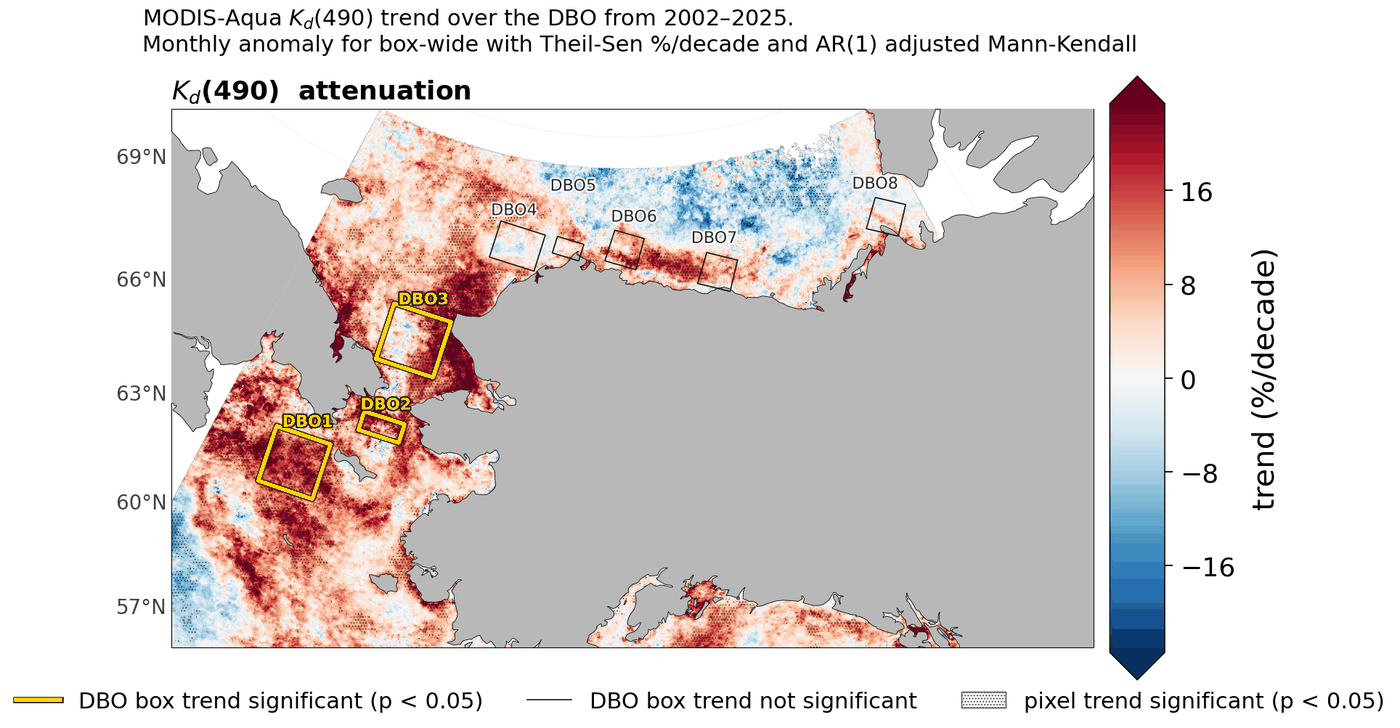

In [23]:
# --- the figure: old-checkpoint Kd(490) map, final title ------------------------
FS_GRID = 20                      # graticule (lat/lon) label size — was 16; draw_panel reads this

panel_h = FIG_W * 0.80 * _panel_aspect(EXTENT)
fig, ax = plt.subplots(1, 1, figsize=(FIG_W, panel_h + 2.6), subplot_kw={"projection": disp})
draw_panel(ax, slope_old, p_old, sig_old, PANEL_LABEL, UNIT_LABEL)

fig.suptitle("MODIS-Aqua $K_d$(490) trend over the DBO from 2002–2025.\n"
             "Monthly anomaly for box-wide with Theil-Sen %/decade and AR(1) adjusted Mann-Kendall",
             fontsize=FS_TITLE - 4, x=0.02, ha="left", y=0.995)

_key = Line2D([0], [0], color=SIG_BOX_COLOR, lw=SIG_BOX_LW,
              label="DBO box trend significant (p < 0.05)")
_key.set_path_effects([pe.Stroke(linewidth=SIG_BOX_LW + 2.2, foreground=SIG_BOX_HALO), pe.Normal()])
handles = [_key,
           Line2D([0], [0], color=NS_BOX_COLOR, lw=NS_BOX_LW, label="DBO box trend not significant"),
           Patch(facecolor="white", edgecolor="0.3", hatch="....", label="pixel trend significant (p < 0.05)")]
fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False, fontsize=FS_LEG,
           bbox_to_anchor=(0.5, 0.004))

fig.subplots_adjust(top=0.90, bottom=0.075, left=0.045, right=0.995)
for ext in ("png", "pdf"):
    fig.savefig(OUT_DIR / f"{OUT_STEM}_oldckpt.{ext}", dpi=200, bbox_inches="tight")
    print("saved", OUT_DIR / f"{OUT_STEM}_oldckpt.{ext}")
plt.show()
